# Extended hBN Slab Above a Perforated Gold Film

As a reference calculation, we consider a geometry inspired by Sheinfux *et al.*, *Nature Materials* **23**, 499–505 (2024): an extended hBN slab above a gold film containing an aperture. For numerical convenience, the square aperture of the original geometry is replaced by a cylindrical air hole, allowing the use of azimuthal symmetry and a two-dimensional simulation domain.

We apply the same few-mode and master-equation workflow used for the hyperbolic cavities. The calculated Purcell spectrum is converted into a dipole-normalized spectral density, represented by a three-mode model, and used to study the effective spectrum and time dynamics of a molecular vibration near the aperture.

Only the narrow spectral window around the relevant resonances is available for this benchmark. We therefore do not perform the broadband perturbative/non-perturbative separation used in the cavity notebooks; the effective model includes the fitted modes and the intrinsic molecular linewidth only. The resulting comparison should consequently be interpreted as a reference.

## Tools and utilities


In [1]:
import os
import pickle

import cmasher as cmr
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import CubicSpline

# Request 64-bit arithmetic before the fitting backend is imported.
os.environ.setdefault("JAX_ENABLE_X64", "True")
plt.style.use("https://johannesfeist.eu/misc/jf_cb.mplstyle")

from methods.plotcolored import plotcolored
from methods.tools import debye_e_nm

## Physical parameters


The calculations use a $1\,\mathrm{D}$ molecular vibration with an intrinsic linewidth of $0.04\,\mathrm{meV}$. 

In [51]:
mu_D = 1.0 
mu_e_nm = mu_D * debye_e_nm
gamma_e_eV = 0.04 * 1e-3   # in eV

## Target spectral window

The available data cover the frequency window around the disk resonance.


In [2]:
file_path = '../data/ref_calculation_Sheinfux_Fp_res44THz.txt'
dataB = np.loadtxt(file_path, skiprows=5)

In [3]:
# The first column is frequency in THz; the second is the Purcell factor.
freq = np.asarray(dataB[:, 0])
Fp = np.asarray(dataB[:, 1])

In [4]:
# define the dipole moment and the homogeneous linewidth of the emitter
mu_D = 1.0 
mu_e_nm = mu_D * debye_e_nm  # dipole moment in e nm
gamma_e_eV = 0.04*1e-3  # eV

# convert the frequency from THz to eV
w = freq / 241.799

k0 = 2.0 * np.pi / (1240 / w)
eps0 = 55.264 * 1e-3  # e^2 eV^-1 nm^-1
# compute free-space spectral density in eV^-1
J0 = k0**3 * mu_e_nm**2 / (6.0 * np.pi**2 * eps0)
# compute the spectral density J(w) in eV^-1
J = Fp * J0

# compute the dipole-moment-normalized spectral density J(w) / mu^2 
Jdivmu2 = J / mu_e_nm**2

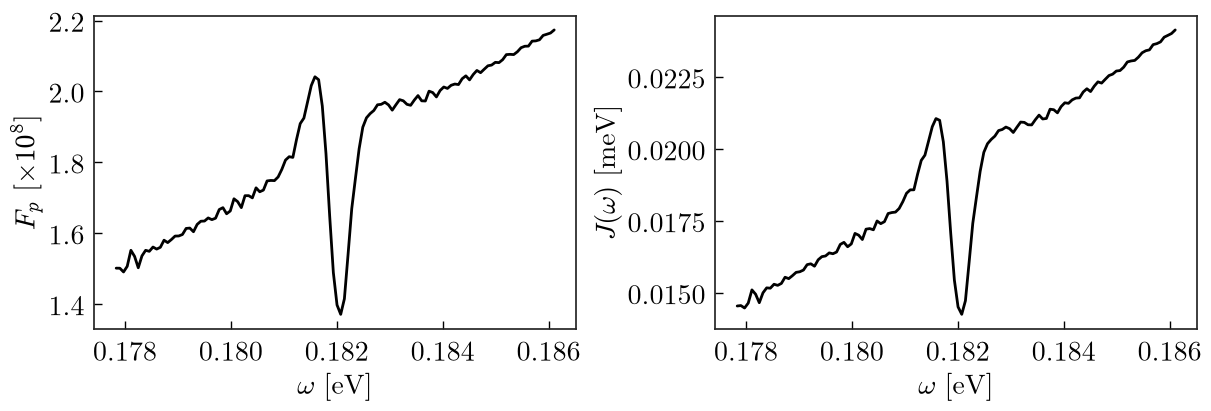

In [5]:
fig, ax = plt.subplots(figsize=(12,4), nrows=1, ncols=2)
ax[0].plot(w, Fp*1e-8, label='Fp')
ax[1].plot(w, J*1e3, label='J')

ax[0].tick_params(axis='both', labelsize=20)
ax[1].tick_params(axis='both', labelsize=20)

ax[0].set_xlabel(r'$\omega$ [eV]', fontsize=20)
ax[1].set_xlabel(r'$\omega$ [eV]', fontsize=20)
ax[0].set_ylabel(r'$F_p$ [$\times 10^8$]', fontsize=20)
ax[1].set_ylabel(r'$J(\omega)$ [meV]', fontsize=20);

## Few-mode fitting

We now fit the calculated spectral density with the few-mode model
$$
    J_\text{fm}(\omega)= \frac{\mu^2}{\pi} \mathrm{Im} \Bigg\{ \vec{g}^{T} \frac{1}{\mathbf{\tilde{H}}-\omega} \vec{g} \Bigg\}.
$$
The non-Hermitian matrix $\tilde{\mathbf{H}}=\omega_{ij}-i\kappa_i\delta_{ij}/2$ contains the coherent mode couplings and Markovian losses. This step follows the treatment of Medina *et al.* (Phys. Rev. Lett. **126**, 093601, 2021).

In [6]:
# import custom module for applying few-mode fitting
from methods.apply_few_mode import FewModeFit

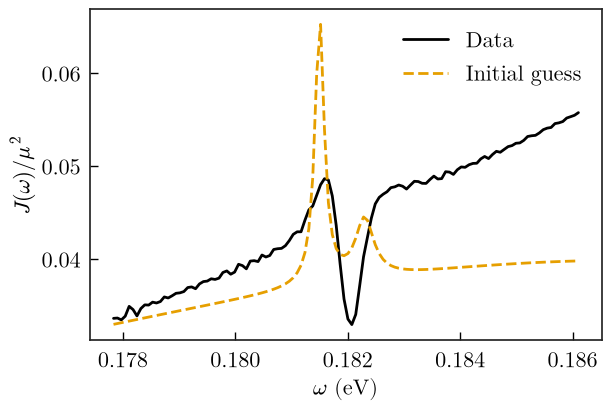

In [10]:
# Initial three-mode energies, linewidths, and normalized couplings (eV).
H = np.diag([0.1815, 0.1823, 0.1870])
Nm = H.shape[0]
K = np.array([2e-4, 4e-4, 400e-4])
g = np.array([[3e-3, 2e-3, 50e-3]])

fmc = FewModeFit(w, Jdivmu2, H, K, g)
fmc.initialize(set_limits=False);

The initial three-mode parameters provide only the starting point for the optimizer. Bounds on the mode eigenvalues are disabled here because the broad high-energy mode lies partly outside the narrow data window.


Fit error: 0.00260684


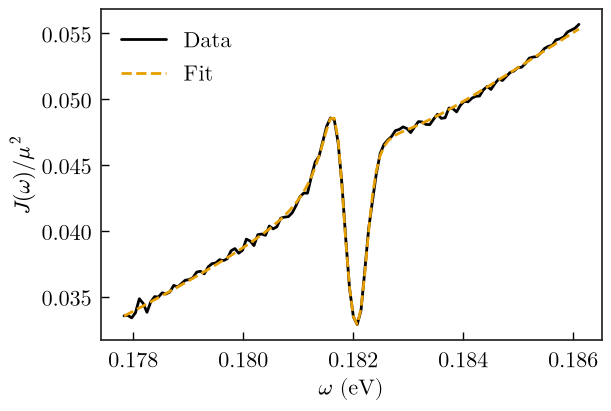

In [11]:
# Optimize the few-mode parameters.
fmc.fit();

After optimization, we diagonalize the lossy Hamiltonian. The complex eigenfrequencies determine the resonance positions and quality factors, while the transformed couplings determine the normalized effective mode volumes.


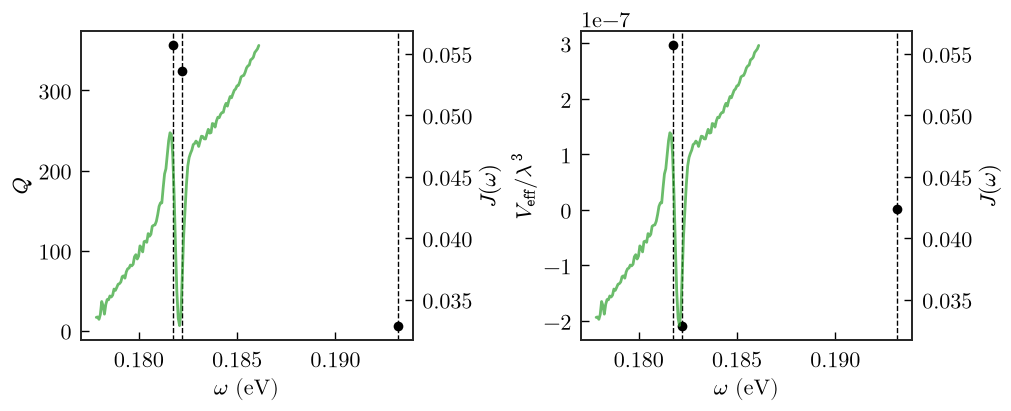

In [12]:
# Diagonalize the fitted lossy Hamiltonian and compute mode figures of merit.
Omega, Q, Veff_norm = fmc.compute_figures_of_merit()

In [13]:
# Complex couplings in the basis of diagonalized lossy modes.
g_tilde = fmc.g_tilde

The two narrow diagonalized modes overlap strongly in this window. The following diagnostic shows their individual contributions and coherent sum, illustrating how the fitted line shape emerges from both modes.


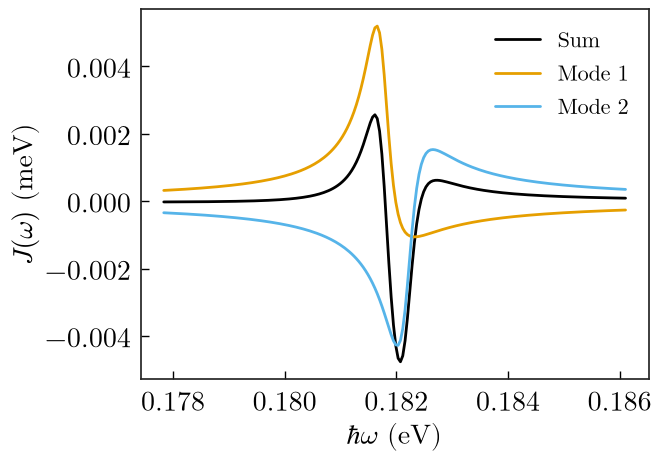

In [14]:
# Isolate the contributions of the two narrow resonances.
mode_indices = (0, 1)
frequency_grid = np.linspace(w[0], w[-1], 200)
mode_spectra = [
    np.imag(g_tilde[index]**2 / (Omega[index] - frequency_grid))
    * mu_e_nm**2 / np.pi
    for index in mode_indices
]

fig, ax = plt.subplots()
ax.plot(frequency_grid, np.sum(mode_spectra, axis=0) * 1e3,
        label='Sum')
for index, spectrum in zip(mode_indices, mode_spectra):
    ax.plot(frequency_grid, spectrum * 1e3, label=rf'Mode {index + 1}')
ax.set_xlabel(r'$\hbar\omega$ (eV)', fontsize=20)
ax.set_ylabel(r'$J(\omega)$ (meV)', fontsize=20)
ax.tick_params(axis='both', labelsize=20)
ax.legend()

In [19]:
# Recover fitted parameters in the original coupled-mode basis.
H, kappas, gs = fmc.fitted_parameters()

In [49]:
data = {
    'fit': {
        'w': w,
        'J': J,
    },
    'coupled_modes': {
        'H': H, 
        'kappas': kappas, 
        'g': gs
    },
    'uncoupled_modes': {
        'Omega': Omega,
        'Q': Q,
        'Veff_norm': Veff_norm,
        'g_tilde': g_tilde,
    },
}

fit_path = 'few_mode_fits/Sheinfux_config_3modes_fit.pickle'
with open(fit_path, 'wb') as handle:
    pickle.dump(data, handle, protocol=pickle.HIGHEST_PROTOCOL)

## Load saved few-mode fitting results (optional)

Run this section to skip the optimization and continue from the saved fit.

In [47]:
fit_path = 'few_mode_fits/Sheinfux_config_3modes_fit.pickle'
with open(fit_path, 'rb') as handle:
    data = pickle.load(handle)

In [50]:
w, J = data['fit']['w'], data['fit']['J']
H = data['coupled_modes']['H']
kappas = data['coupled_modes']['kappas']
gs = data['coupled_modes']['g']
Nm = kappas.shape[0]

## Spectrum of the effective Hamiltonian

The effective model contains the fitted three-mode environment, a $1\,\mathrm{D}$ emitter, and its intrinsic linewidth. We diagonalize

$$\hat{\mathcal H}_\mathrm{eff}=\hat H_\mathrm{S}-\frac{i}{2}\sum_i\kappa_i\hat a_i^\dagger\hat a_i-\frac{i}{2}\gamma_e\hat b^\dagger\hat b$$

while sweeping the emitter transition across the fitted window.


In [21]:
from methods.mastereq import MasterEquationQtp

In [22]:
meq = MasterEquationQtp(Nm=Nm, Ne=1, Nexc=1)
meq.provide_fm_pars(H, gs, kappas);

In [24]:
we_ls = np.linspace(w[0], w[-1], 50)
vals, vecs = meq.get_Heff_dispersion(
    we_ls, mu=mu_e_nm, gamma_e=gamma_e_eV
)

The dispersion branches are coloured by their emitter weight $|c_e|^2$. This separates predominantly photonic branches from the hybridized branch carrying appreciable molecular character.


(0.1775, 0.186)

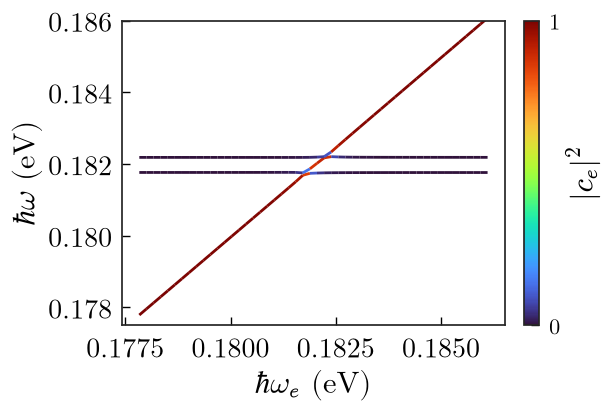

In [27]:
fig, ax = plt.subplots(figsize=(6, 4))
norm = plt.matplotlib.colors.Normalize(0, 1)
for branch in range(1, vals.shape[1]):
    # Colour each branch by the emitter population of its eigenvector.
    image = plotcolored(
        ax, we_ls, vals[:, branch].real,
        np.abs(vecs[:, 1, branch])**2, norm=norm,
    )
ax.autoscale()
ax.set_xlabel(r'$\hbar\omega_e$ (eV)', fontsize=22)
ax.set_ylabel(r'$\hbar\omega$ (eV)', fontsize=22)
colorbar = plt.colorbar(image, ax=ax)
colorbar.set_label(r'$|c_e|^2$', fontsize=22)
colorbar.set_ticks([0, 1])
ax.tick_params(axis='both', labelsize=20)
ax.set_ylim(0.1775, 0.186)

Estimated Rabi Splitting is:	 0.066 meV
Transition frequency of the QE is:	 0.18172 eV


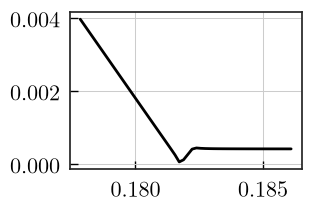

In [39]:
# find splitting
spl = vals[:,2].real - vals[:,1].real
fig, ax = plt.subplots(figsize=(3,2))
ax.plot(we_ls, spl)
ax.grid()

indx2 = np.where(spl == np.min(spl))
print(f"Estimated Rabi Splitting is:\t {np.min(spl)*1e3:.3f} meV")
print(f"Transition frequency of the QE is:\t {we_ls[indx2][0]:.5f} eV")

Estimated Rabi Splitting is:	 0.033 meV
Transition frequency of the QE is:	 0.18222 eV


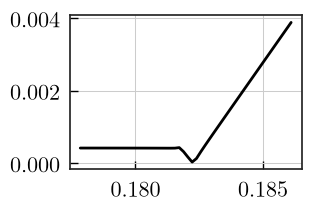

In [40]:
# find splitting
spl = vals[:,3].real - vals[:,2].real
fig, ax = plt.subplots(figsize=(3,2))
ax.plot(we_ls, spl)
ax.grid()

indx2 = np.where(spl == np.min(spl))
print(f"Estimated Rabi Splitting is:\t {np.min(spl)*1e3:.3f} meV")
print(f"Transition frequency of the QE is:\t {we_ls[indx2][0]:.5f} eV")

## Time dynamics

Finally, we tune the emitter to the transition energy selected by the minimum-splitting analysis and propagate an initially excited molecular vibration. The single-excitation restriction is sufficient for these linear-response dynamics.


In [ ]:
meq = MasterEquationQtp(Nm=Nm, Ne=1, Nexc=1)

In [41]:
# Tune the emitter to the energy selected from the avoided-crossing analysis.
meq.provide_fm_pars(H, gs, kappas)
meq.set_qe_pars(omega_e=0.18222, mu=mu_e_nm, gamma_e=gamma_e_eV)
meq.setup_ops()
meq.initial_state()

Quantum object: dims=[[2, 2, 2, 2], [1]], shape=(5, 1), type='ket', dtype=Dense
Qobj data =
[[0.]
 [1.]
 [0.]
 [0.]
 [0.]]

In [42]:
tsfs, sol = meq.solve(t_max=4e4, n_t=1000)

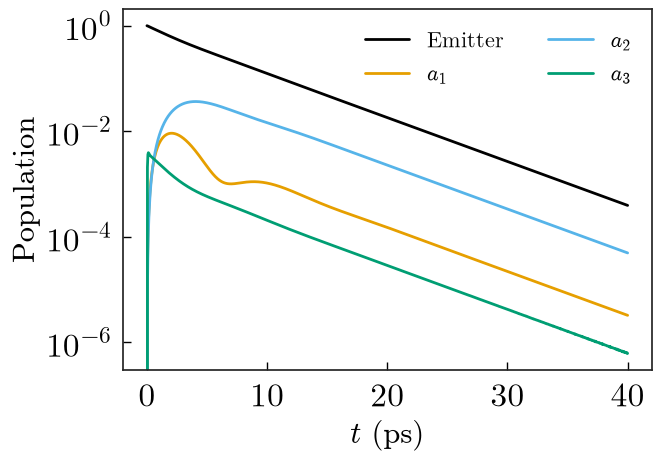

In [45]:
fig, ax = plt.subplots()
ax.plot(tsfs*1e-3, sol.expect[-1], label="Emitter")
for ii in range(Nm):
    ax.plot(tsfs*1e-3, sol.expect[ii], label=r"$a_{%i}$" % (ii+1))
ax.set_xlabel(r"$t \text{ (ps)}$", fontsize=22)
ax.set_ylabel(r"$\text{Population}$", fontsize=22)
ax.tick_params(axis='both', labelsize=24)
ax.legend(ncol=2);
ax.set_yscale('log')